# Lab 4 — Classical ML baseline
**Concepts:** 7 classical features and SVM / Random Forest · 8 accuracy, precision, recall, F1, macro-F1, confusion matrix. Runtime: CPU.

Before deep learning, describe each tile with numbers a person designed, then fit simple classifiers. This is
the cheap baseline every later model must beat.

| Family | What it measures | Dims |
|---|---|---|
| HOG | direction of edges in 16×16-pixel cells (cracks and LP are oriented edges) | 1,764 |
| LBP | micro-texture: each pixel vs its 8 or 16 neighbours, as a histogram | 28 |
| GLCM | how often grey levels co-occur at distance 1, 3, 5: contrast, homogeneity, energy, correlation | 12 |
| Intensity | 32-bin brightness histogram + mean, std, 5/50/95th percentile | 37 |

**Metrics.** *Precision* of a class = of the tiles we called CR, how many were CR. *Recall* = of the real CR tiles,
how many we found (for a defect: 1 − missed-defect rate). *F1* = harmonic mean of the two. *Macro-F1* = plain
average of the per-class F1s, so the rare LP class counts as much as CR. The *confusion matrix* shows which
class gets mistaken for which.

In [1]:
# ---- Setup: identical in every notebook ------------------------------------
# Finds the project folder (Google Drive in Colab, or D:\weld_insp locally),
# makes src/ importable, fixes the random seed.
import os, sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/weld_insp")
else:
    ROOT = Path(os.environ.get("WELD_ROOT", Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
os.environ["WELD_ROOT"] = str(ROOT)
sys.path.insert(0, str(ROOT / "src"))
QUICK = os.environ.get("WELD_QUICK") == "1"   # tiny smoke-test mode, leave off for real runs

from weld_insp.config import get_paths, set_seed, CLASSES, SEED
P = get_paths()
P.show()
set_seed(SEED)

root          weld_insp
data          weld_insp/data
results       weld_insp/results
figures       weld_insp/results/figures
checkpoints   weld_insp/checkpoints
work          weld_insp/data
riawelc       weld_insp/data/riawelc
gdxray        weld_insp/data/gdxray
gdxray_crops  weld_insp/data/gdxray_crops


In [2]:
import time, joblib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.base import clone
from weld_insp.data import get_riawelc
from weld_insp.features import extract_all, FEATURE_FAMILIES
from weld_insp.metrics import summary, classification_report_df, plot_confusion, log_result
from weld_insp.config import CLASS_TO_IDX

RIA = get_riawelc(P)
table = pd.read_csv(P.results / "image_table.csv")         # all 24,407 rows (original split)
clean = pd.read_csv(P.results / "clean_split.csv")         # 21,964 unique rows (leakage-free split)
print(len(table), len(clean))

24407 21964


## Task 1 — features
Extracted once for all 24,407 tiles (≈ 10 min on 2 CPU cores) and saved; the row order matches `image_table.csv`.

In [3]:
feat_f = P.results / "features.npy"
if feat_f.exists():
    X_all = np.load(feat_f)
else:
    t0 = time.time()
    X_all = extract_all([RIA / p for p in table.path], workers=os.cpu_count())
    np.save(feat_f, X_all)
    print(f"extracted in {time.time() - t0:.0f}s")
print("feature matrix", X_all.shape, "| families:", {k: v.stop - v.start for k, v in FEATURE_FAMILIES.items()})
row_of = pd.Series(np.arange(len(table)), index=table.path)
N_PCA = 32 if QUICK else 256

def xy(df, split):
    d = df[df.split == split]
    if QUICK:
        d = d.sample(frac=1, random_state=SEED).groupby("label").head(60)
    return X_all[row_of[d.path].values], d.label.map(CLASS_TO_IDX).values

Xtr, ytr = xy(clean, "train"); Xva, yva = xy(clean, "val"); Xte, yte = xy(clean, "test")
print("clean split sizes:", len(ytr), len(yva), len(yte))

feature matrix (24407, 1841) | families: {'HOG': 1764, 'LBP': 28, 'GLCM': 12, 'INTENSITY': 37}


clean split sizes: 15369 3296 3299


**Model selection on validation only.** Each candidate setting is trained on *train* and scored on *val*
(macro-F1); the test split is used once, at the end. The scaler (and PCA) are fitted on training data only,
inside a pipeline, so no information from val/test leaks into the preprocessing.

For the SVM, the 1,841 standardised features are first reduced to 256 principal components. An RBF-SVM on
15k × 1,841 is slow (its cost grows with the square of the sample count times the dimension); PCA keeps
about 80% of the variance (printed below) and makes each fit take seconds. The Random Forest uses all features, because we want
its importances per feature family.

In [4]:
def fit_eval(model, name):
    t0 = time.time(); model.fit(Xtr, ytr); fit_s = time.time() - t0
    s = summary(yva, model.predict(Xva))
    print(f"{name:28s} val macro-F1 {s['macro_f1']:.4f}  acc {s['accuracy']:.4f}  ({fit_s:.0f}s)")
    return model, s["macro_f1"]

svm_grid = {}
for C in [1, 10, 100]:
    svm_grid[C] = fit_eval(make_pipeline(StandardScaler(), PCA(N_PCA, random_state=SEED),
                                         SVC(kernel="rbf", C=C, gamma="scale")), f"SVM RBF C={C}")
best_C = max(svm_grid, key=lambda c: svm_grid[c][1]); svm = svm_grid[best_C][0]

rf_grid = {}
for n in [100, 300, 500]:
    rf_grid[n] = fit_eval(make_pipeline(StandardScaler(), RandomForestClassifier(
        n_estimators=n, max_features="sqrt", n_jobs=-1, random_state=SEED)), f"Random Forest {n} trees")
best_n = max(rf_grid, key=lambda n: rf_grid[n][1]); rf = rf_grid[best_n][0]
print(f"\nChosen on validation: SVM C={best_C}, Random Forest {best_n} trees")
pca = svm.named_steps["pca"]
print(f"PCA({N_PCA}) keeps {pca.explained_variance_ratio_.sum():.1%} of the variance")

SVM RBF C=1                  val macro-F1 0.6338  acc 0.6380  (16s)


SVM RBF C=10                 val macro-F1 0.6655  acc 0.6650  (20s)


SVM RBF C=100                val macro-F1 0.6652  acc 0.6647  (20s)


Random Forest 100 trees      val macro-F1 0.6326  acc 0.6380  (81s)


Random Forest 300 trees      val macro-F1 0.6315  acc 0.6380  (189s)


Random Forest 500 trees      val macro-F1 0.6365  acc 0.6429  (341s)

Chosen on validation: SVM C=10, Random Forest 500 trees
PCA(256) keeps 80.5% of the variance


## Task 2 — results on the clean test split (touched once)

In [5]:
models = {
    f"SVM RBF (C={best_C})": svm,
    f"Random Forest ({best_n} trees)": rf,
    "Gaussian NB (equal priors)": make_pipeline(StandardScaler(), GaussianNB(priors=[0.25] * 4)).fit(Xtr, ytr),
    "Gaussian NB (priors from train)": make_pipeline(StandardScaler(), GaussianNB()).fit(Xtr, ytr),
}
rows, preds = [], {}
for name, m in models.items():
    p_tr, p_te = m.predict(Xtr), m.predict(Xte)
    preds[name] = p_te
    s = summary(yte, p_te)
    rows.append({"model": name, "split": "clean", "train_acc": round(summary(ytr, p_tr)["accuracy"], 4),
                 "test_acc": s["accuracy"], "test_macro_f1": s["macro_f1"],
                 **{k: v for k, v in s.items() if k.startswith(("recall_", "f1_"))}})
    log_result(P.results, {"lab": 4, "model": name, "train_split": "clean", "eval_set": "RIAWELC test (clean)", **s})
baseline = pd.DataFrame(rows)
baseline

,model,split,train_acc,test_acc,test_macro_f1,recall_CR,f1_CR,recall_PO,f1_PO,recall_LP,f1_LP,recall_ND,f1_ND
0,SVM RBF (C=10),clean,1.0000,0.6126,0.6117,0.4305,0.5040,0.6859,0.6295,0.6257,0.5659,0.7384,0.7475
1,Random Forest (500 trees),clean,1.0000,0.5177,0.5164,0.5158,0.4444,0.2262,0.2827,0.6329,0.6213,0.7176,0.7172
2,Gaussian NB (equal priors),clean,0.6005,0.5208,0.4949,0.2168,0.3555,0.7629,0.5334,0.3129,0.3288,0.8056,0.7618
3,Gaussian NB (priors from train),clean,0.6002,0.5208,0.4946,0.2168,0.3555,0.7653,0.5342,0.3100,0.3268,0.8056,0.7618


In [6]:
for name in list(models)[:2]:
    print(f"\n{name}"); display(classification_report_df(yte, preds[name]))


SVM RBF (C=10)


,precision,recall,f1,support
CR,0.6077,0.4305,0.5040,950.0
PO,0.5816,0.6859,0.6295,831.0
LP,0.5165,0.6257,0.5659,700.0
ND,0.7569,0.7384,0.7475,818.0
macro (present classes),0.6157,0.6201,0.6117,3299.0
accuracy,NaN,NaN,0.6126,3299.0



Random Forest (500 trees)


,precision,recall,f1,support
CR,0.3904,0.5158,0.4444,950.0
PO,0.3768,0.2262,0.2827,831.0
LP,0.6102,0.6329,0.6213,700.0
ND,0.7167,0.7176,0.7172,818.0
macro (present classes),0.5235,0.5231,0.5164,3299.0
accuracy,NaN,NaN,0.5177,3299.0


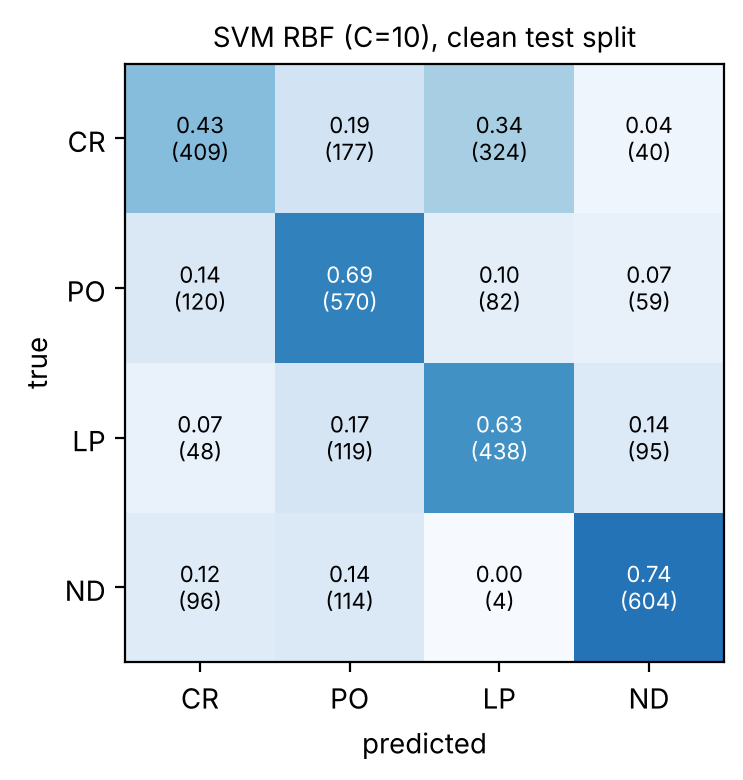

In [7]:
best_name = baseline.loc[baseline.test_macro_f1.idxmax(), "model"]
plot_confusion(yte, preds[best_name], title=f"{best_name}, clean test split",
               save=P.figures / "04_confusion_best_classical.png")
plt.show()

**Most-missed class: CR (crack), recall 0.43 for the SVM; 34% of cracks are called LP.** Lab 1 showed why: both a
crack and lack of penetration appear as a dark line, and many cracks are faint. HOG sees "an oriented dark edge" in
both; what separates them (LP is straight, horizontal and spans the tile; a crack is thin, kinked, any direction) is
shape over the whole tile, which cell-level descriptors capture poorly. ND is easiest (recall 0.74), consistent
with its distinct brightness range (Lab 1).

Both SVM and RF reach **100% training accuracy** but ~52–61% on test plates: they fit the training plates, not
the defect types.

### The same models on the original (leaky) split
Trained on the official training folder and tested on the official test folder, which Lab 2 showed is
made of exact copies of training tiles.

In [8]:
Xtr_o, ytr_o = xy(table, "train"); Xte_o, yte_o = xy(table, "test")
for name, m in list(models.items())[:2]:
    m_o = clone(m).fit(Xtr_o, ytr_o)                              # same settings, untrained copy
    s = summary(yte_o, m_o.predict(Xte_o))
    rows.append({"model": name, "split": "original", "train_acc": round(summary(ytr_o, m_o.predict(Xtr_o))["accuracy"], 4),
                 "test_acc": s["accuracy"], "test_macro_f1": s["macro_f1"],
                 **{k: v for k, v in s.items() if k.startswith(("recall_", "f1_"))}})
    log_result(P.results, {"lab": 4, "model": name, "train_split": "original", "eval_set": "RIAWELC test (original)", **s})
baseline = pd.DataFrame(rows)
baseline.to_csv(P.results / "baseline_metrics.csv", index=False)
baseline[["model", "split", "train_acc", "test_acc", "test_macro_f1"]]

,model,split,train_acc,test_acc,test_macro_f1
0,SVM RBF (C=10),clean,1.0000,0.6126,0.6117
1,Random Forest (500 trees),clean,1.0000,0.5177,0.5164
2,Gaussian NB (equal priors),clean,0.6005,0.5208,0.4949
3,Gaussian NB (priors from train),clean,0.6002,0.5208,0.4946
4,SVM RBF (C=10),original,1.0000,1.0000,1.0000
5,Random Forest (500 trees),original,1.0000,1.0000,1.0000


## Task 3 — One-vs-One vs One-vs-Rest, and feature importance
scikit-learn's `SVC` is One-vs-One inside: one SVM per pair of classes (6 for 4 classes), then a vote.
One-vs-Rest trains one SVM per class against all others (4 SVMs).

In [9]:
ovr = make_pipeline(StandardScaler(), PCA(N_PCA, random_state=SEED),
                    OneVsRestClassifier(SVC(kernel="rbf", C=best_C, gamma="scale"), n_jobs=-1)).fit(Xtr, ytr)
ovo_s, ovr_s = summary(yte, svm.predict(Xte)), summary(yte, ovr.predict(Xte))
ovo_ovr = pd.DataFrame([{"strategy": "One-vs-One (6 SVMs)", **ovo_s}, {"strategy": "One-vs-Rest (4 SVMs)", **ovr_s}])
ovo_ovr.to_csv(P.results / "svm_ovo_vs_ovr.csv", index=False)
ovo_ovr[["strategy", "accuracy", "macro_f1"] + [c for c in ovo_ovr if c.startswith("recall_")]]

,strategy,accuracy,macro_f1,recall_CR,recall_PO,recall_LP,recall_ND
0,One-vs-One (6 SVMs),0.6126,0.6117,0.4305,0.6859,0.6257,0.7384
1,One-vs-Rest (4 SVMs),0.6229,0.6199,0.4295,0.6895,0.6500,0.7567


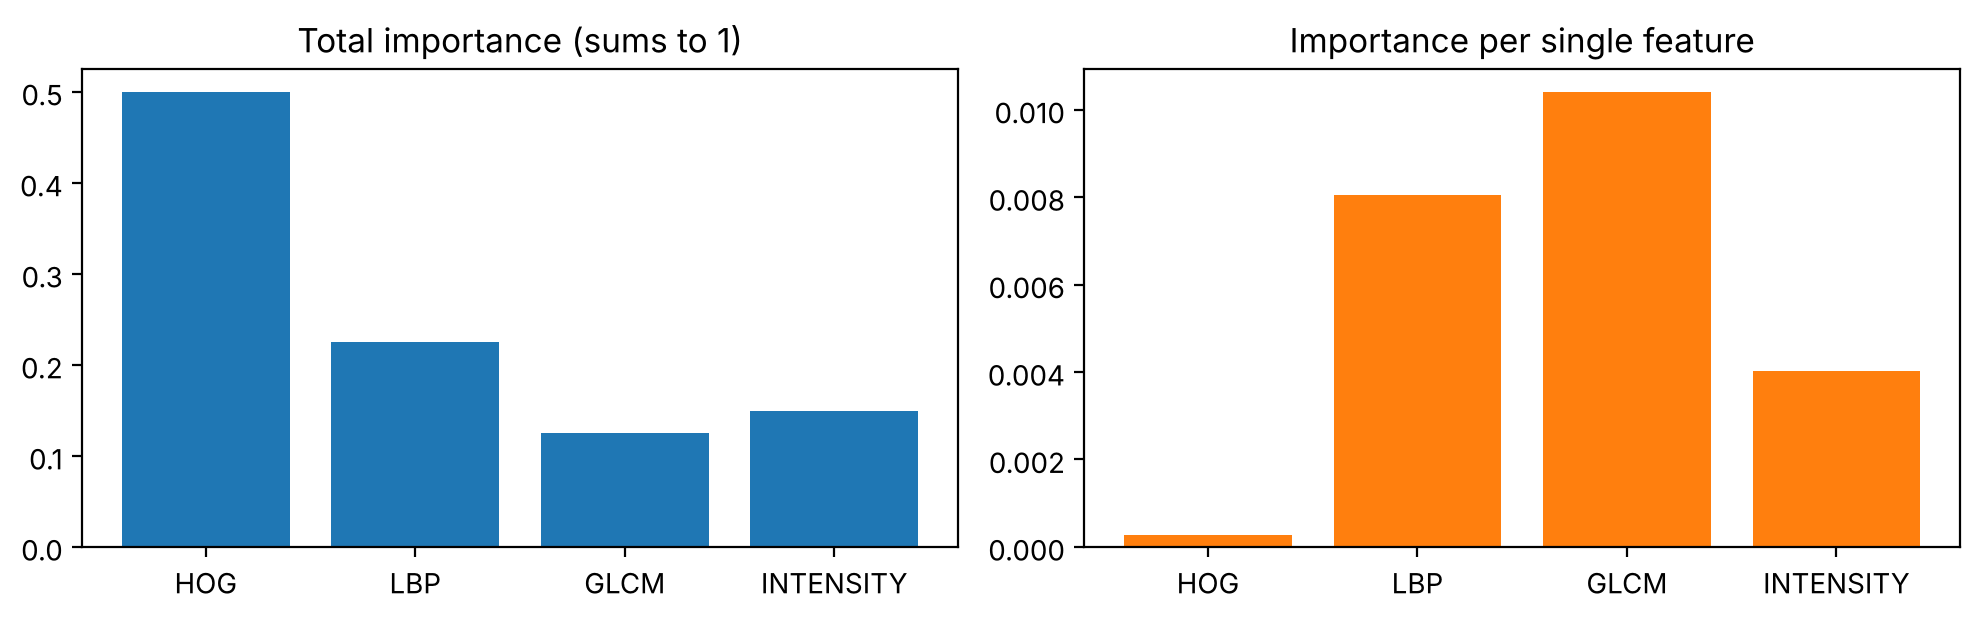

,family,n_features,total_importance,mean_per_feature
0,HOG,1764,0.500,0.00028
1,LBP,28,0.225,0.00805
2,GLCM,12,0.125,0.01041
3,INTENSITY,37,0.149,0.00403


In [10]:
imp = rf.named_steps["randomforestclassifier"].feature_importances_
fam = pd.DataFrame([{"family": k, "n_features": v.stop - v.start, "total_importance": imp[v].sum(),
                     "mean_per_feature": imp[v].mean()} for k, v in FEATURE_FAMILIES.items()])
fam["total_importance"] = fam.total_importance.round(3); fam["mean_per_feature"] = fam.mean_per_feature.round(5)
fam.to_csv(P.results / "rf_feature_family_importance.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].bar(fam.family, fam.total_importance); ax[0].set_title("Total importance (sums to 1)")
ax[1].bar(fam.family, fam.mean_per_feature, color="tab:orange"); ax[1].set_title("Importance per single feature")
plt.tight_layout(); plt.savefig(P.figures / "04_rf_feature_importance.png", dpi=130); plt.show()
fam

**One-vs-One vs One-vs-Rest:** within one point of each other (One-vs-Rest slightly ahead), so the multi-class
strategy is not what limits the SVM.

**Feature families:** HOG gets half of the total importance only because it has 1,764 of the 1,841 features. Per
single feature, **GLCM** (texture co-occurrence) and **LBP** (micro-texture) matter most, roughly 30–40× more than a
single HOG cell. Texture statistics carry most of the signal per number.

In [11]:
joblib.dump(svm, P.checkpoints / "classical_svm.joblib")
joblib.dump(rf, P.checkpoints / "classical_rf.joblib")
print("saved models for Lab 7")

saved models for Lab 7


## Notes
- **Did:** extracted HOG, LBP, GLCM and intensity features (1,841 per tile), chose SVM C and RF trees on validation, and compared SVM, RF and two Gaussian NB variants on the clean split and on the original split.
- **Found:** the best classical model (SVM RBF, C=10) scores **61.3% accuracy, 0.612 macro-F1** on unseen plates. The same models score **100.0%** on the official test split, because that split is copies of training tiles.
- **Found:** cracks are missed most (recall 0.43), mostly confused with lack of penetration; ND is easiest. Per feature, texture (GLCM, LBP) beats HOG.
- **Surprised me:** a classical SVM "matches" the published deep-learning accuracy on the official split, which is a direct demonstration that the 99% figures measure leakage, not model quality.